# Do Women's World Cup Matches Score More Goals?

**Question:** are more goals scored in women's international soccer matches than in men's?

The analysis uses official **FIFA World Cup** matches (no qualifiers) played since **2002-01-01**: 384 men's and 200 women's matches, 584 in total.

- $H_0$: the mean number of goals in women's matches is the same as in men's matches.
- $H_A$: the mean number of goals in women's matches is greater than in men's matches.
- Significance level: $\alpha = 0.10$

**Data:** `men_results.csv` and `women_results.csv` (see [`../data/README.md`](../data/README.md)).

In [1]:
import pandas as pd
import pingouin as pg

DATA_DIR = "../data/"

men_results = pd.read_csv(DATA_DIR + 'men_results.csv', parse_dates=['date'])
women_results = pd.read_csv(DATA_DIR + 'women_results.csv', parse_dates=['date'])

men_results.head(), women_results.head()

(   Unnamed: 0       date home_team away_team  home_score  away_score  \
 0           0 1872-11-30  Scotland   England           0           0   
 1           1 1873-03-08   England  Scotland           4           2   
 2           2 1874-03-07  Scotland   England           2           1   
 3           3 1875-03-06   England  Scotland           2           2   
 4           4 1876-03-04  Scotland   England           3           0   
 
   tournament  
 0   Friendly  
 1   Friendly  
 2   Friendly  
 3   Friendly  
 4   Friendly  ,
    Unnamed: 0       date home_team  away_team  home_score  away_score  \
 0           0 1969-11-01     Italy     France           1           0   
 1           1 1969-11-01   Denmark    England           4           3   
 2           2 1969-11-02   England     France           2           0   
 3           3 1969-11-02     Italy    Denmark           3           1   
 4           4 1975-08-25  Thailand  Australia           3           2   
 
          tournam

## 1. Filter World Cup matches since 2002 and compute total goals

In [2]:
# Official FIFA World Cup matches only
international_men = men_results[men_results['tournament'] == 'FIFA World Cup']
international_women = women_results[women_results['tournament'] == 'FIFA World Cup']

# Matches played since 2002-01-01
international_fut_men = international_men[international_men['date'] >= '2002-01-01'].copy()
international_fut_women = international_women[international_women['date'] >= '2002-01-01'].copy()

# Total goals per match
international_fut_men['total_score'] = international_fut_men['home_score'] + international_fut_men['away_score']
international_fut_women['total_score'] = international_fut_women['home_score'] + international_fut_women['away_score']

print(f"Men's matches: {len(international_fut_men)}")
print(f"Women's matches: {len(international_fut_women)}")

Men's matches: 384
Women's matches: 200


## 2. Check the distribution of goals

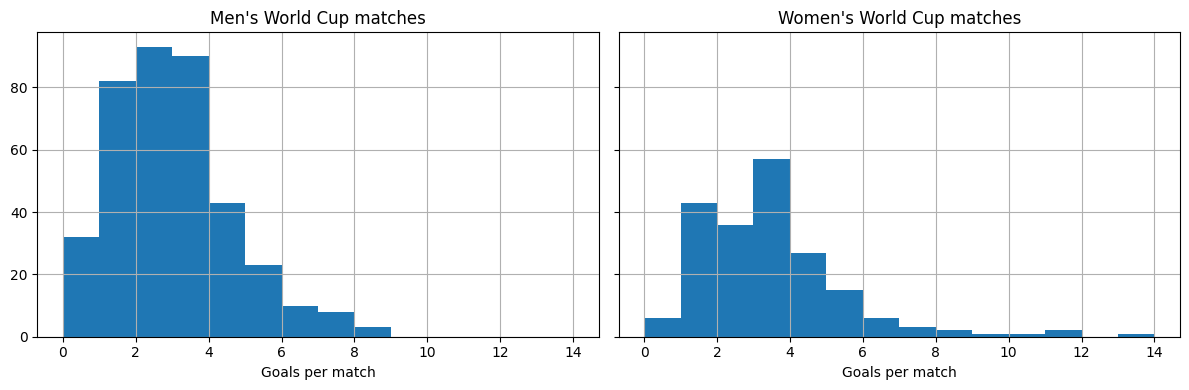

In [3]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
international_fut_men['total_score'].hist(ax=axes[0], bins=range(0, 15))
axes[0].set_title("Men's World Cup matches")
axes[0].set_xlabel('Goals per match')
international_fut_women['total_score'].hist(ax=axes[1], bins=range(0, 15))
axes[1].set_title("Women's World Cup matches")
axes[1].set_xlabel('Goals per match')
plt.tight_layout()
plt.show()

In [4]:
# Does every goal count have at least 30 observations?
tour_score_men = international_fut_men[['tournament', 'total_score']]
tour_score_women = international_fut_women[['tournament', 'total_score']]

counts_men = tour_score_men['total_score'].value_counts()
counts_women = tour_score_women['total_score'].value_counts()

(counts_men >= 30).all(), (counts_women >= 30).all()

(np.False_, np.False_)

The goal counts are right-skewed, not normally distributed, and several goal values have fewer than 30 observations. A parametric t-test is not appropriate, so the analysis uses the non-parametric **Mann-Whitney U test** (one-sided, `alternative='greater'`).

## 3. Mann-Whitney U test

In [5]:
alpha = 0.1
resultado = pg.mwu(x=tour_score_women['total_score'], y=tour_score_men['total_score'], alternative='greater')

# The p-value column is 'p-val' before pingouin 0.6 and 'p_val' from 0.6 on
p_col = 'p-val' if 'p-val' in resultado.columns else 'p_val'
p_val = resultado[p_col].iloc[0]
p_val

np.float64(0.005106609825443641)

In [6]:
result = 'reject' if p_val <= alpha else 'fail to reject'
result_dict = {"p_val": p_val, "result": result}
result_dict

{'p_val': np.float64(0.005106609825443641), 'result': 'reject'}

## Conclusion

The p-value (≈ 0.005) is below the 10% significance level, so the null hypothesis is **rejected**: there is statistical evidence that more goals are scored in women's FIFA World Cup matches than in men's since 2002.